# Investigating specificity information in Chai-1 Scores

In this notebook, we investigate the ability of chai-1 confidence scores at discriminating between binding and non-binding TCR:pMHC complexes.

In [1]:
import glob
import os
import re

import anarci
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import ranksums
from sklearn.metrics import roc_auc_score

from tcr_pmhc_predicted_structures.utils import IMGT_CDR, IMGT_MHC_TCR_CONTACT_POSITIONS, MHC_I_IMGT_BETA_HELIX_START

In [2]:
CHAIN_ORDER = ('mhc_chain_1', 'mhc_chain_2', 'antigen_chain', 'alpha_chain', 'beta_chain')

In [3]:
chai_scores = []

for path in glob.glob('../data/interim/structures-chai-restraints/*/scores.model_idx_*.npz'):
    with np.load(path) as scores:
        score = {}

        score['structure_name'] = os.path.basename(os.path.dirname(path))
        score['model_number'] = int(re.match(r'scores.model_idx_(\d+).npz', os.path.basename(path)).group(1))

        for key, val in scores.items():
            if val.shape == (1,):
                score[key] = val[0]

        for chain_name, chain_ptm in zip(CHAIN_ORDER, scores['per_chain_ptm'].T, strict=True):
            score[chain_name + '_ptm'] = chain_ptm[0]

        for chain_name_1, chain_iptms in zip(CHAIN_ORDER, scores['per_chain_pair_iptm'][0], strict=True):
            for chain_name_2, iptm in zip(CHAIN_ORDER, chain_iptms, strict=True):
                if chain_name_1 != chain_name_2:
                    score[chain_name_1 + '_' + chain_name_2 + '_iptm'] = iptm

        chai_scores.append(score)

chai_scores = pd.DataFrame(chai_scores)

In [4]:
chai_scores['type'] = chai_scores['structure_name'].map(lambda name: 'decoy' if '_' in name else 'binder')
chai_scores['label'] = chai_scores['structure_name'].map(lambda name: 0 if '_' in name else 1)

In [5]:
ptm_columns = chai_scores.filter(regex='ptm').columns

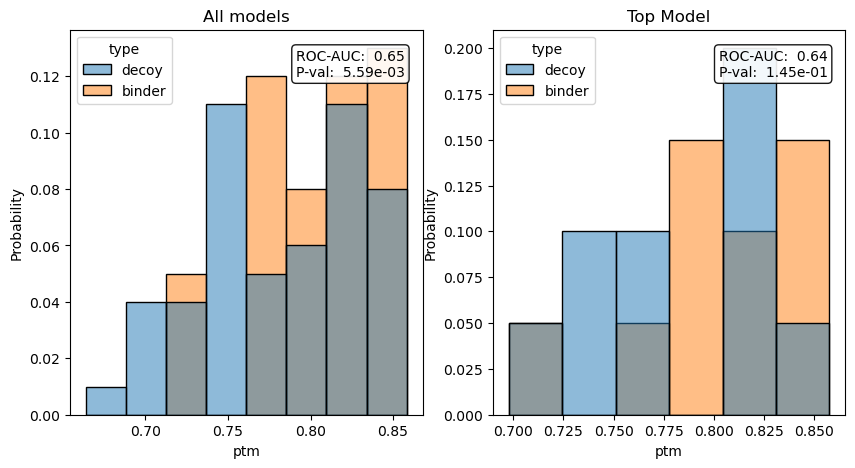

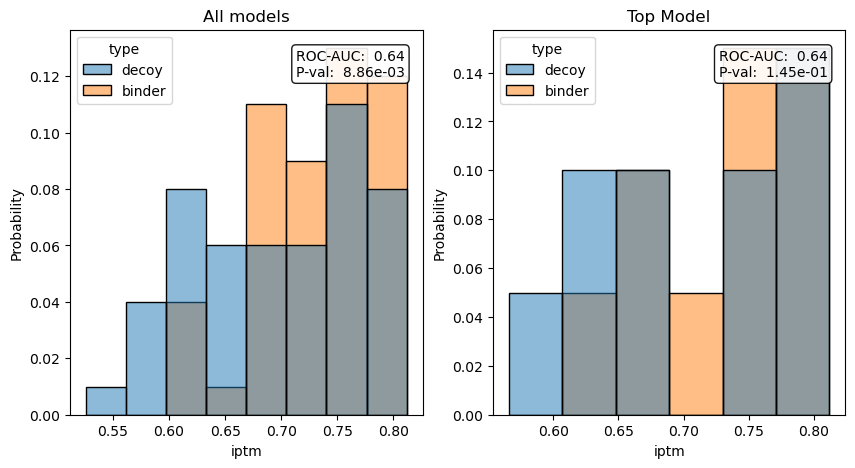

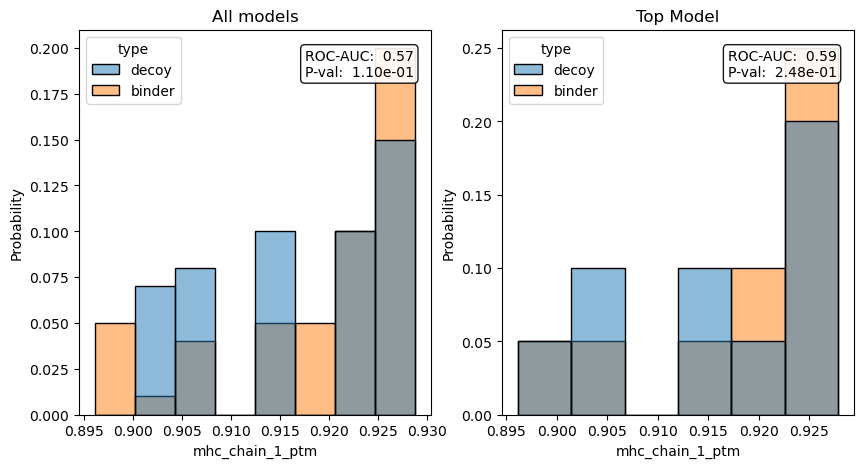

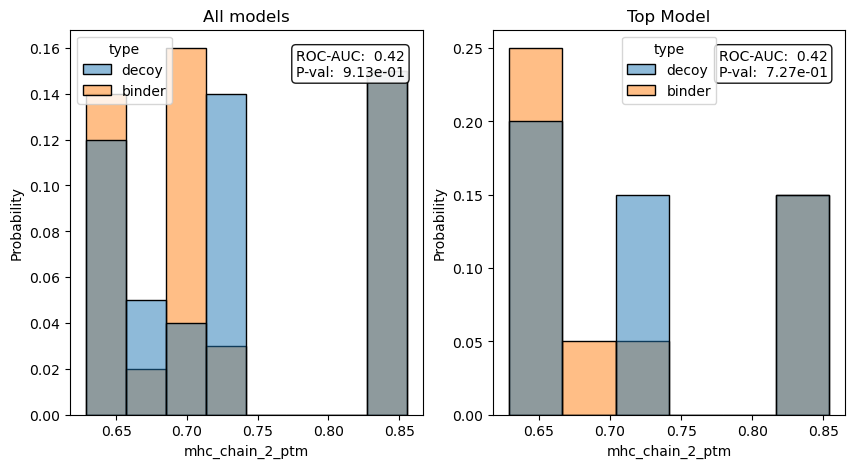

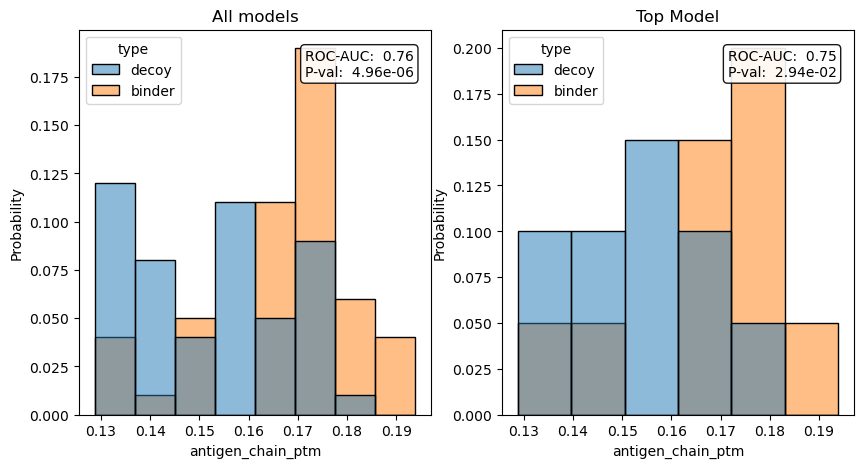

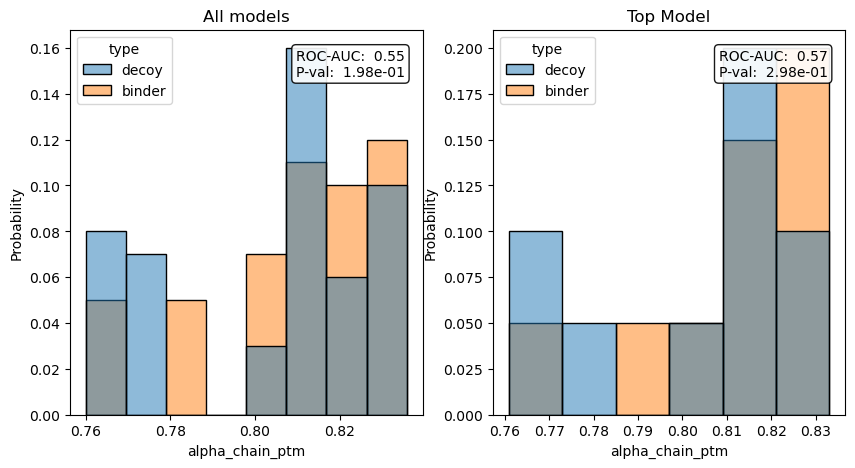

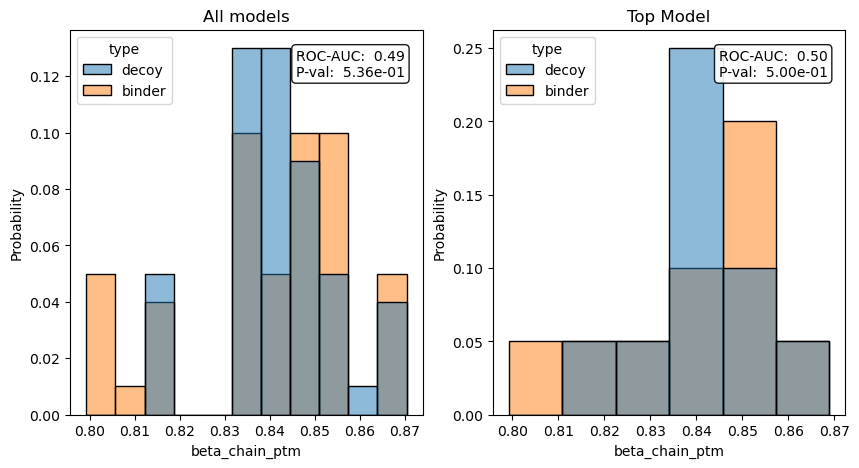

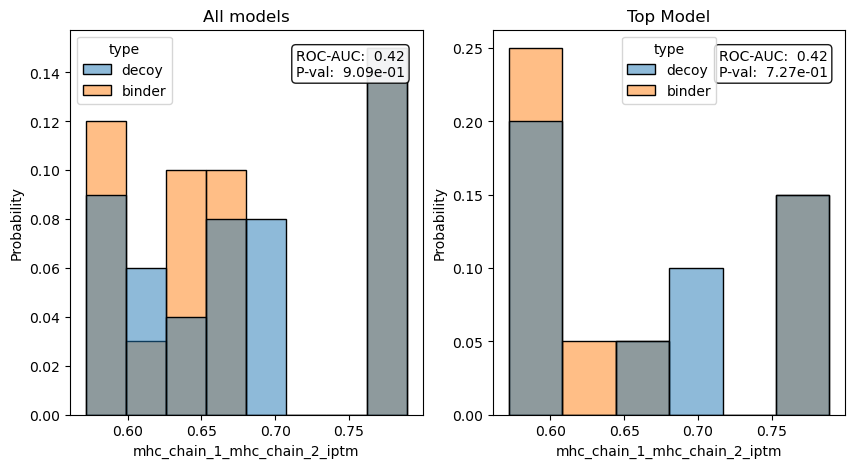

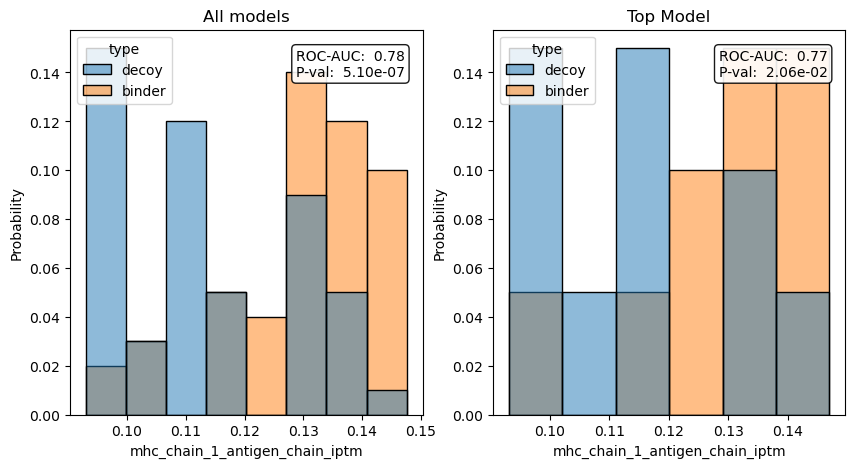

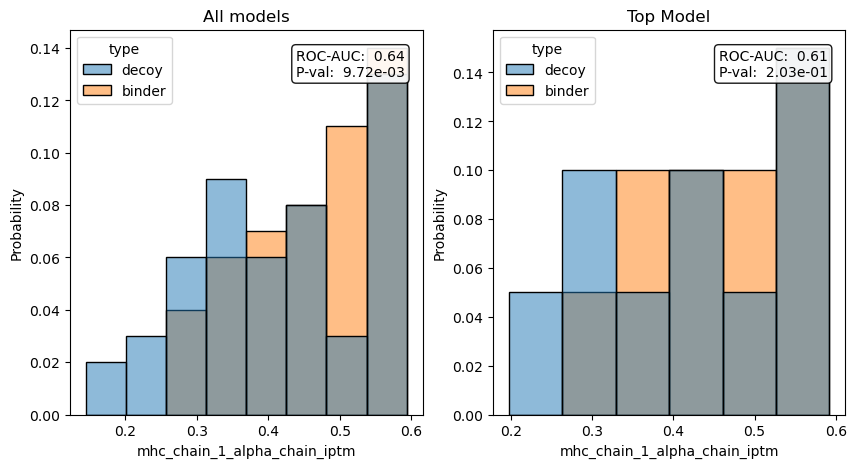

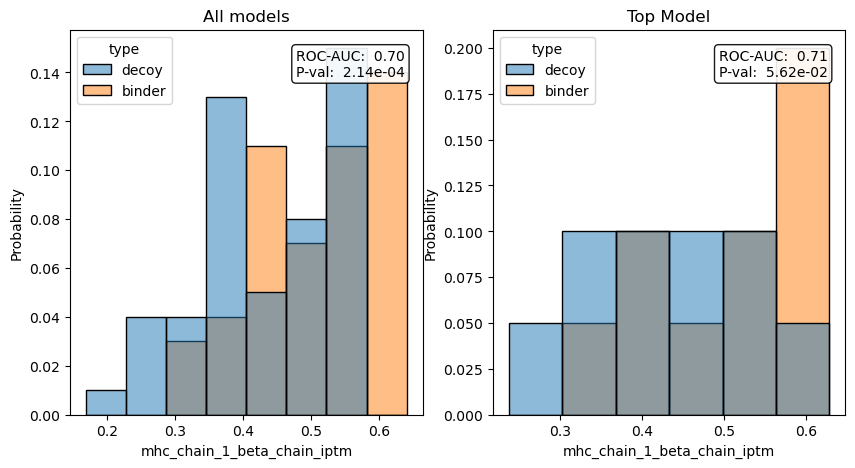

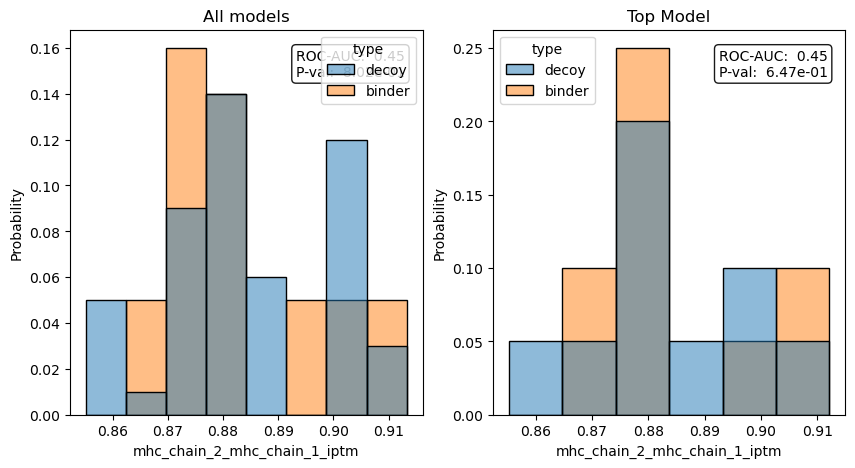

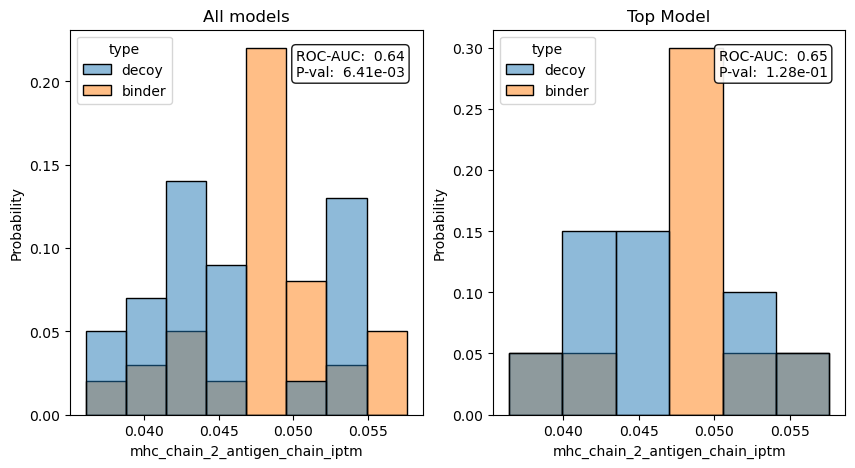

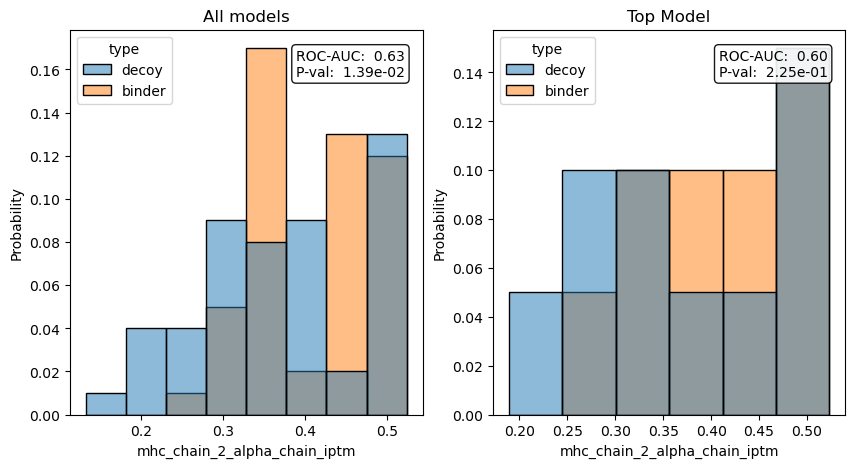

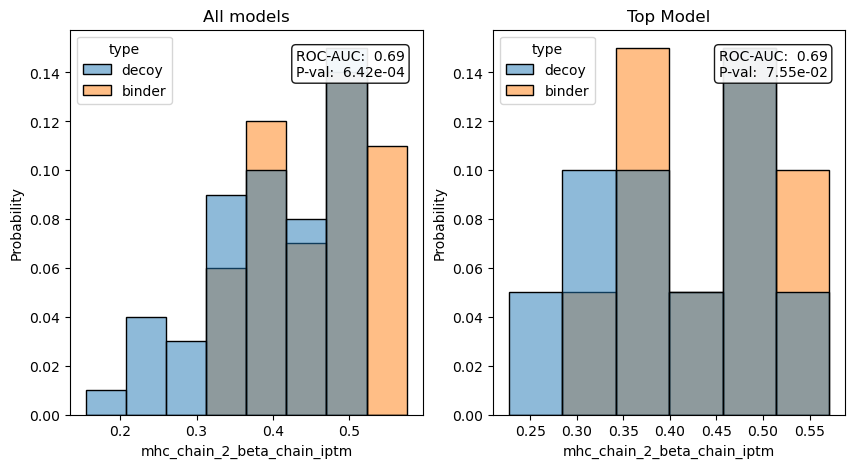

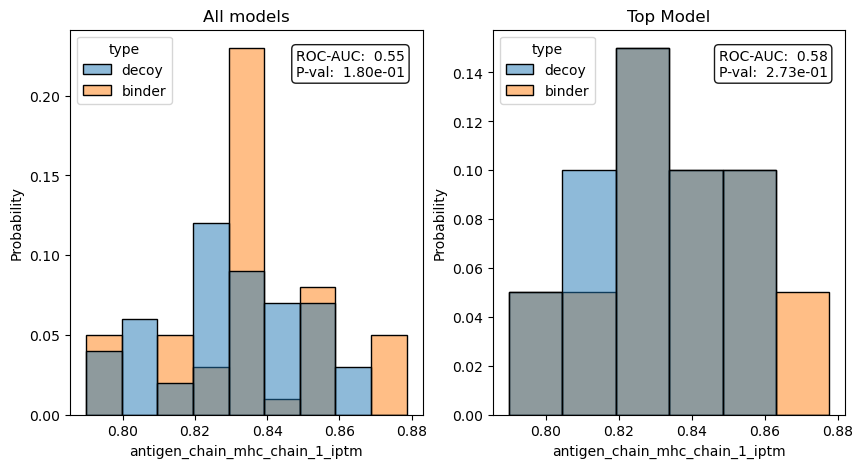

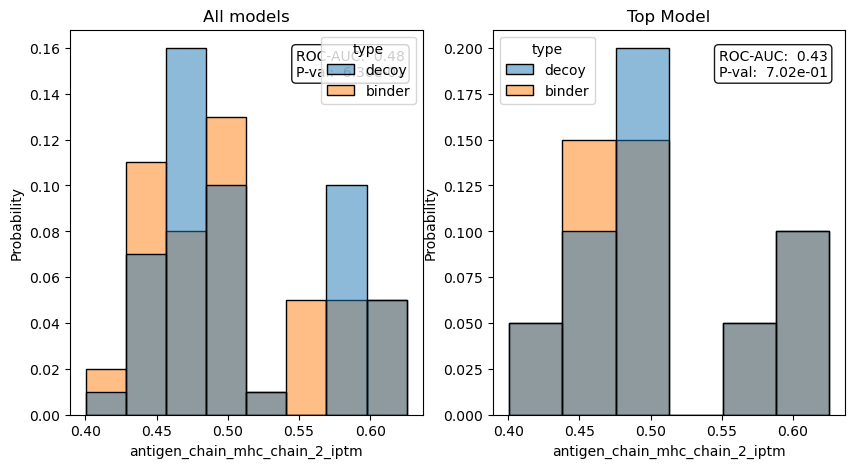

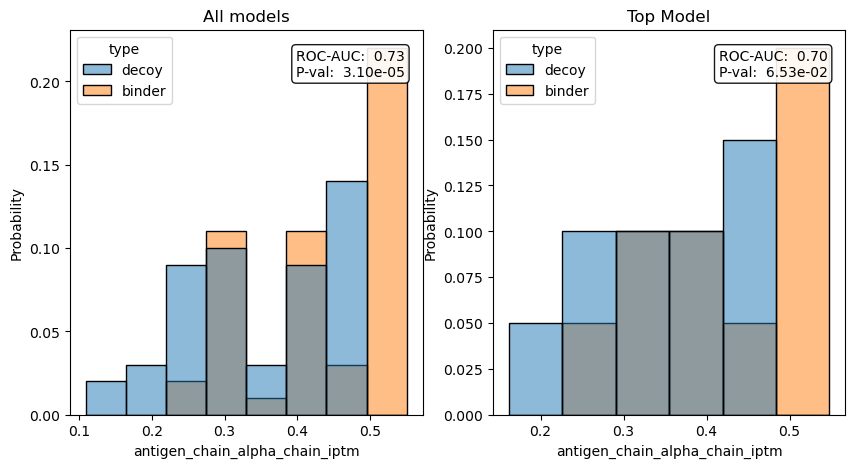

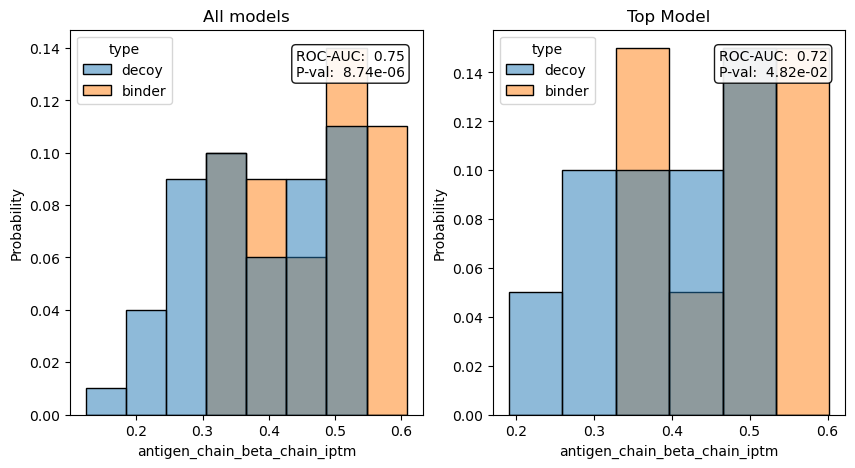

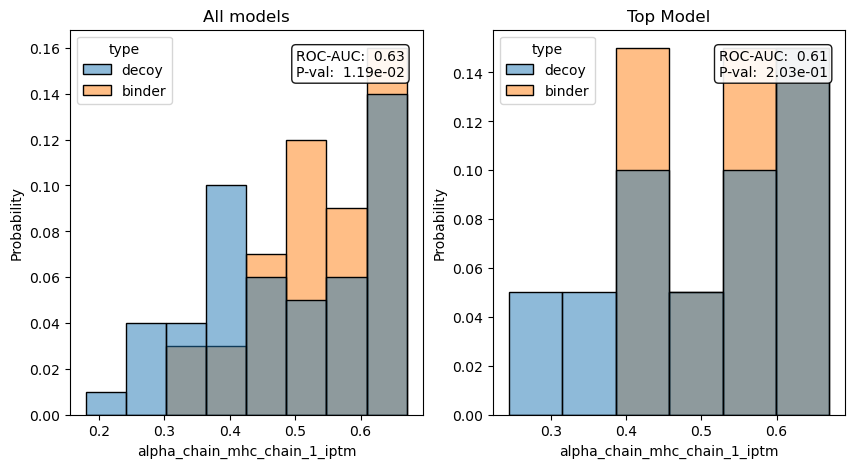

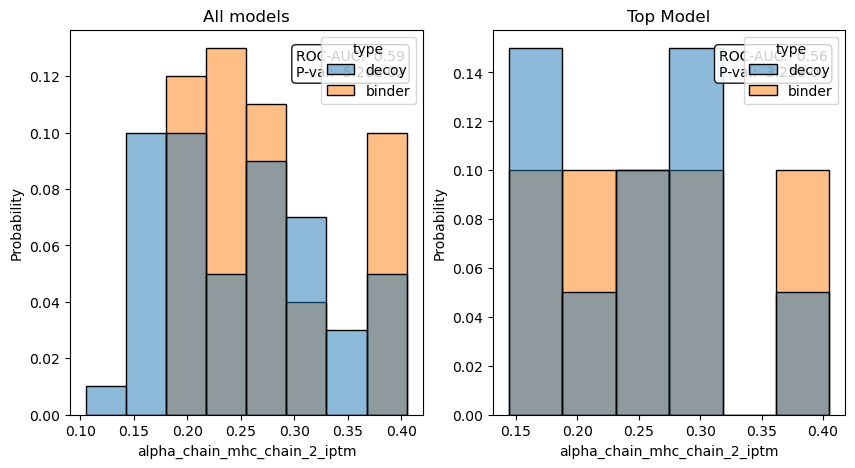

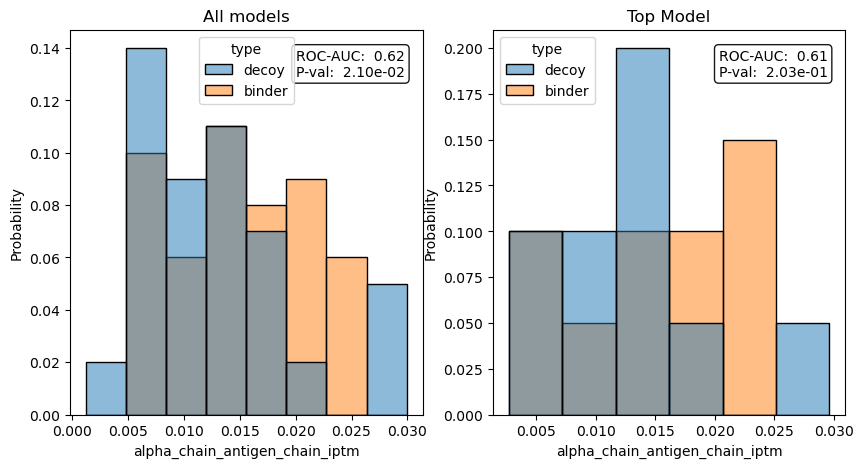

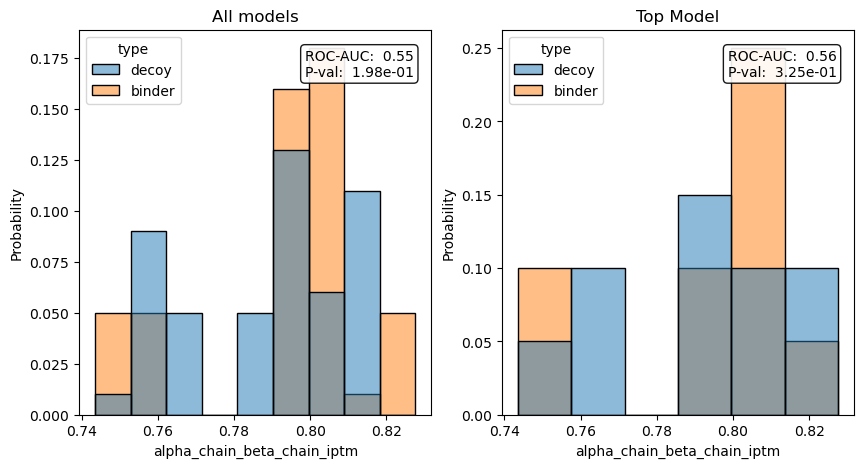

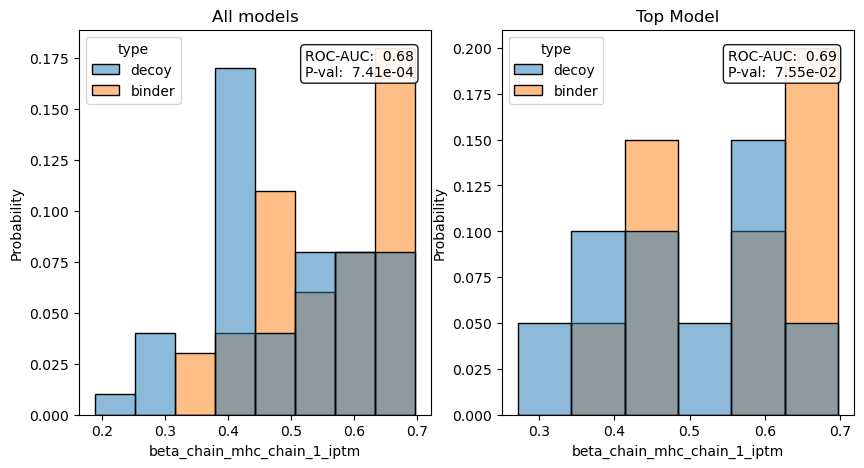

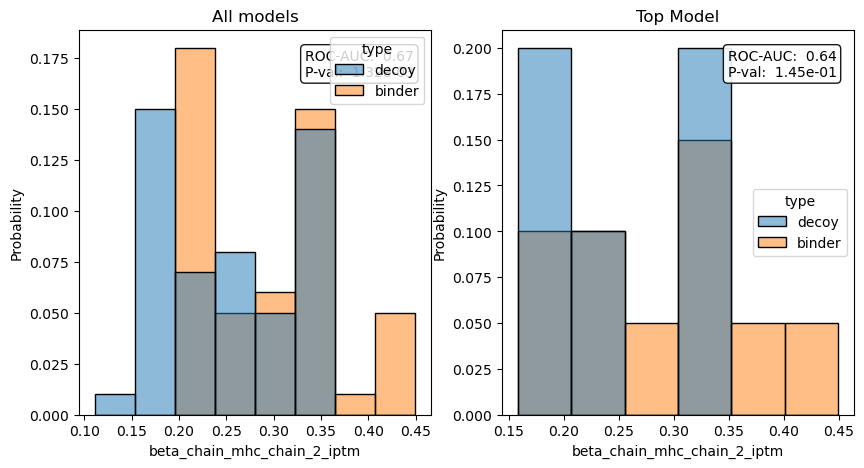

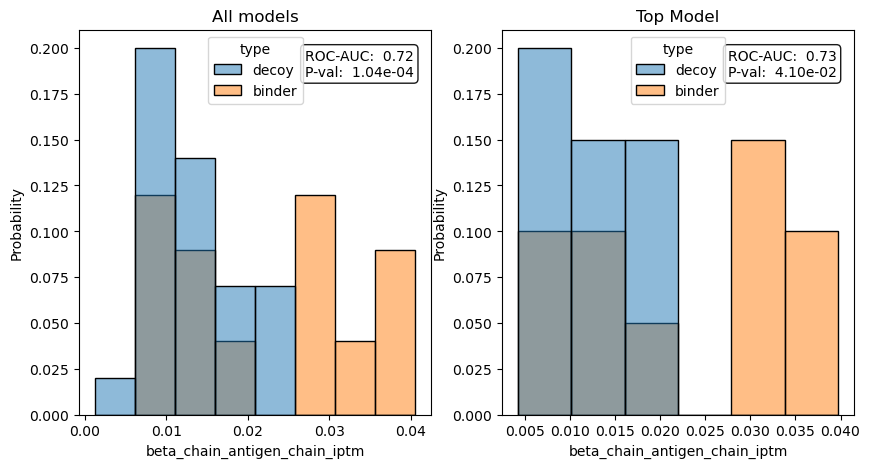

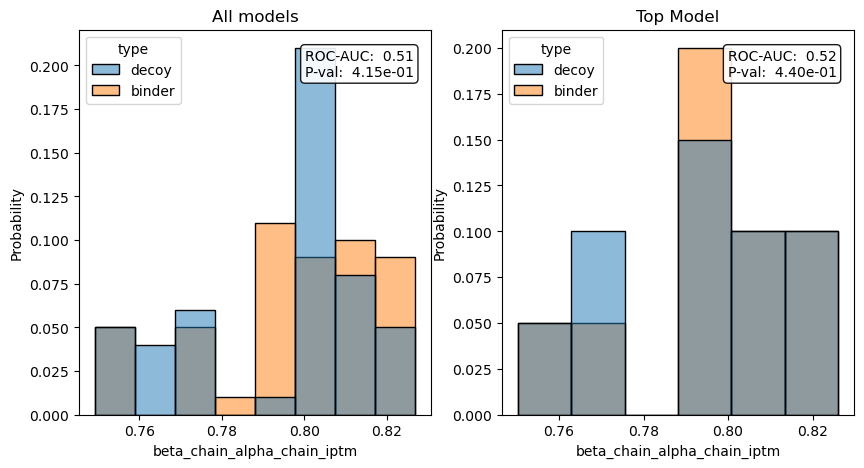

In [6]:
scores_summary = []

for ptm_column in ptm_columns:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
    score_summary = {
        'metric': ptm_column,
    }

    # All Models
    roc = roc_auc_score(chai_scores['label'], chai_scores[ptm_column])
    stat, p_val = ranksums(
        chai_scores.query("type == 'binder'")[ptm_column],
        chai_scores.query("type == 'decoy'")[ptm_column],
        alternative='greater',
    )
    score_summary['roc_all_models'] = roc
    score_summary['stat_all_models'] = stat
    score_summary['p_val_all_models'] = p_val

    sns.histplot(chai_scores, x=ptm_column, hue='type', stat='probability', ax=ax1)
    ax1.set_title('All models')
    ax1.text(
        0.95,
        0.95,
        f'ROC-AUC: {roc: .2f}\nP-val: {p_val: .2e}',
        transform=ax1.transAxes,
        verticalalignment='top',
        horizontalalignment='right',
        bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
    )

    # Top Model
    roc = roc_auc_score(
        chai_scores.query('model_number == 0')['label'], chai_scores.query('model_number == 0')[ptm_column]
    )
    stat, p_val = ranksums(
        chai_scores.query("model_number == 0 and type == 'binder'")[ptm_column],
        chai_scores.query("model_number == 0 and type == 'decoy'")[ptm_column],
        alternative='greater',
    )
    score_summary['roc_model_number == 0'] = roc
    score_summary['stat_model_number == 0'] = stat
    score_summary['p_val_top_model'] = p_val

    ax2.text(
        0.95,
        0.95,
        f'ROC-AUC: {roc: .2f}\nP-val: {p_val: .2e}',
        transform=ax2.transAxes,
        verticalalignment='top',
        horizontalalignment='right',
        bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
    )
    sns.histplot(chai_scores.query('model_number == 0'), x=ptm_column, hue='type', stat='probability', ax=ax2)
    ax2.set_title('Top Model')

    plt.show()
    scores_summary.append(score_summary)

scores_summary = pd.DataFrame(scores_summary)

In [7]:
scores_summary.sort_values('roc_all_models', ascending=False).set_index('metric')

,roc_all_models,stat_all_models,p_val_all_models,roc_model_number == 0,stat_model_number == 0,p_val_top_model
metric,,,,,,
mhc_chain_1_antigen_chain_iptm,0.7836,4.887718,5.100568e-07,0.77,2.041008,0.020625
antigen_chain_ptm,0.7564,4.418939,4.959342e-06,0.75,1.889822,0.029391
antigen_chain_beta_chain_iptm,0.7492,4.294850,8.740583e-06,0.72,1.663044,0.048152
antigen_chain_alpha_chain_iptm,0.7324,4.005309,3.096819e-05,0.70,1.511858,0.065285
beta_chain_antigen_chain_iptm,0.7152,3.708875,1.040910e-04,0.73,1.738637,0.041049
mhc_chain_1_beta_chain_iptm,0.7044,3.522742,2.135535e-04,0.71,1.587451,0.056205
mhc_chain_2_beta_chain_iptm,0.6868,3.219414,6.422647e-04,0.69,1.436265,0.075463
beta_chain_mhc_chain_1_iptm,0.6844,3.178051,7.413434e-04,0.69,1.436265,0.075463
beta_chain_mhc_chain_2_iptm,0.6744,3.005705,1.324828e-03,0.64,1.058301,0.144959


In [8]:
chai_scores['combined_iptm'] = chai_scores.filter(regex='(antigen_chain|mhc_chain_1)_(alpha|beta)_chain_iptm').apply(
    'mean', axis=1
)

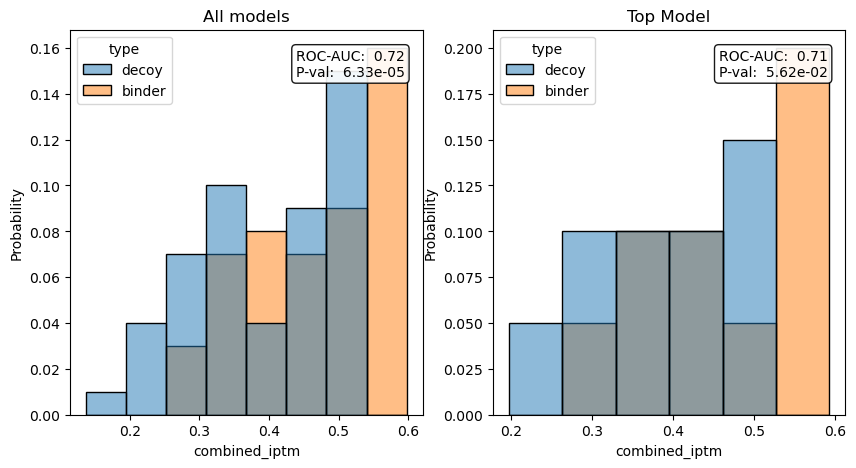

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

roc = roc_auc_score(chai_scores['label'], chai_scores['combined_iptm'])
stat, p_val = ranksums(
    chai_scores.query("type == 'binder'")['combined_iptm'],
    chai_scores.query("type == 'decoy'")['combined_iptm'],
    alternative='greater',
)

sns.histplot(chai_scores, x='combined_iptm', hue='type', stat='probability', ax=ax1)
ax1.set_title('All models')
ax1.text(
    0.95,
    0.95,
    f'ROC-AUC: {roc: .2f}\nP-val: {p_val: .2e}',
    transform=ax1.transAxes,
    verticalalignment='top',
    horizontalalignment='right',
    bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
)

# Top Model
roc = roc_auc_score(
    chai_scores.query('model_number == 0')['label'], chai_scores.query('model_number == 0')['combined_iptm']
)
stat, p_val = ranksums(
    chai_scores.query("model_number == 0 and type == 'binder'")['combined_iptm'],
    chai_scores.query("model_number == 0 and type == 'decoy'")['combined_iptm'],
    alternative='greater',
)

ax2.text(
    0.95,
    0.95,
    f'ROC-AUC: {roc: .2f}\nP-val: {p_val: .2e}',
    transform=ax2.transAxes,
    verticalalignment='top',
    horizontalalignment='right',
    bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
)
sns.histplot(chai_scores.query('model_number == 0'), x='combined_iptm', hue='type', stat='probability', ax=ax2)
ax2.set_title('Top Model')

plt.show()

## PAE Based specificity

In [10]:
confidence_scores = []

for path in glob.glob('../data/interim/structures-chai-restraints/*/confidences.model_idx_*.npz'):
    confidence_score = {}

    with np.load(path) as fh:
        confidence = dict(fh)

    structure_name = os.path.basename(os.path.dirname(path))
    model_number = int(re.match(r'confidences.model_idx_(\d+).npz', os.path.basename(path)).group(1))

    confidence_score['structure_name'] = structure_name
    confidence_score['model_number'] = model_number

    with open(f'../data/interim/sequences-and-restraints-chai/{structure_name}.fasta', 'r') as fh:
        sequences = [line.strip() for line in fh if not line.startswith('>')]

    confidence_numbering = list(
        enumerate(
            (
                (chain_type, residue)
                for chain_type, sequence in zip(CHAIN_ORDER, sequences, strict=True)
                for residue in sequence
            ),
            0,
        )
    )

    tcr_idxs = np.array(
        [idx for idx, (chain_id, _) in confidence_numbering if chain_id in ('alpha_chain', 'beta_chain')]
    )
    pmhc_idxs = np.array(
        [idx for idx, (chain_id, _) in confidence_numbering if chain_id in ('mhc_chain_1', 'antigen_chain')]
    )

    confidence_score['tcr_pmhc_pae_score'] = np.mean(np.array(confidence['pae'])[np.ix_(tcr_idxs, pmhc_idxs)])
    confidence_score['tcr_pmhc_pde_score'] = np.mean(np.array(confidence['pde'])[np.ix_(tcr_idxs, pmhc_idxs)])
    confidence_score['tcr_pmhc_plddt_score'] = np.mean(
        np.array(confidence['plddt'])[np.concatenate([tcr_idxs, pmhc_idxs])]
    )

    confidence_scores.append(confidence_score)

confidence_scores = pd.DataFrame(confidence_scores)

In [11]:
chai_scores = chai_scores.merge(confidence_scores, how='inner', on=['structure_name', 'model_number'])

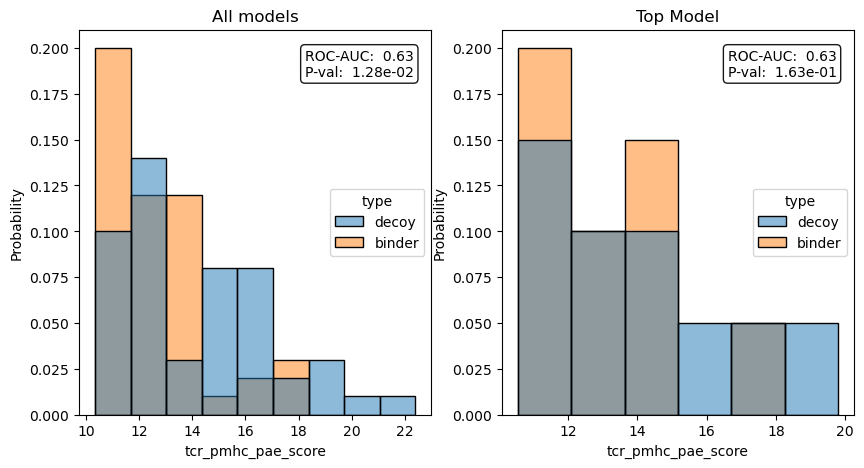

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

roc = 1 - roc_auc_score(chai_scores['label'], chai_scores['tcr_pmhc_pae_score'])
stat, p_val = ranksums(
    chai_scores.query("type == 'binder'")['tcr_pmhc_pae_score'],
    chai_scores.query("type == 'decoy'")['tcr_pmhc_pae_score'],
    alternative='less',
)

sns.histplot(chai_scores, x='tcr_pmhc_pae_score', hue='type', stat='probability', ax=ax1)
ax1.set_title('All models')
ax1.text(
    0.95,
    0.95,
    f'ROC-AUC: {roc: .2f}\nP-val: {p_val: .2e}',
    transform=ax1.transAxes,
    verticalalignment='top',
    horizontalalignment='right',
    bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
)

# Top Model
roc = 1 - roc_auc_score(
    chai_scores.query('model_number == 0')['label'], chai_scores.query('model_number == 0')['tcr_pmhc_pae_score']
)
stat, p_val = ranksums(
    chai_scores.query("model_number == 0 and type == 'binder'")['tcr_pmhc_pae_score'],
    chai_scores.query("model_number == 0 and type == 'decoy'")['tcr_pmhc_pae_score'],
    alternative='less',
)

ax2.text(
    0.95,
    0.95,
    f'ROC-AUC: {roc: .2f}\nP-val: {p_val: .2e}',
    transform=ax2.transAxes,
    verticalalignment='top',
    horizontalalignment='right',
    bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
)
sns.histplot(chai_scores.query('model_number == 0'), x='tcr_pmhc_pae_score', hue='type', stat='probability', ax=ax2)
ax2.set_title('Top Model')

plt.show()

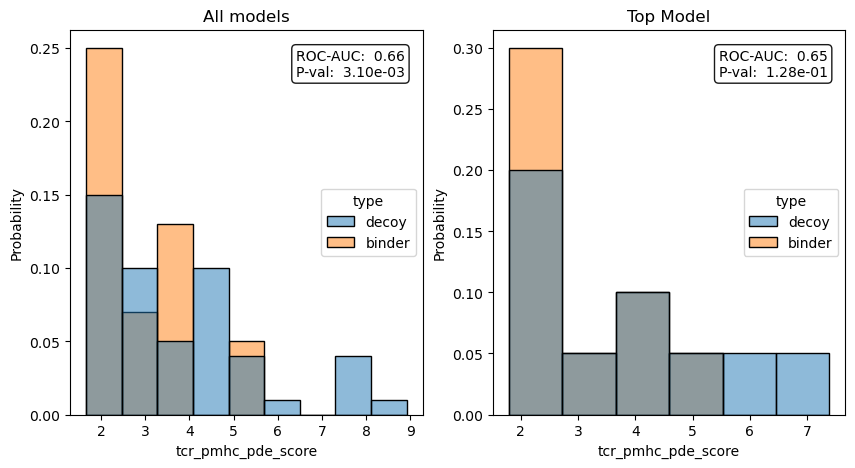

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

roc = 1 - roc_auc_score(chai_scores['label'], chai_scores['tcr_pmhc_pde_score'])
stat, p_val = ranksums(
    chai_scores.query("type == 'binder'")['tcr_pmhc_pde_score'],
    chai_scores.query("type == 'decoy'")['tcr_pmhc_pde_score'],
    alternative='less',
)

sns.histplot(chai_scores, x='tcr_pmhc_pde_score', hue='type', stat='probability', ax=ax1)
ax1.set_title('All models')
ax1.text(
    0.95,
    0.95,
    f'ROC-AUC: {roc: .2f}\nP-val: {p_val: .2e}',
    transform=ax1.transAxes,
    verticalalignment='top',
    horizontalalignment='right',
    bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
)

# Top Model
roc = 1 - roc_auc_score(
    chai_scores.query('model_number == 0')['label'], chai_scores.query('model_number == 0')['tcr_pmhc_pde_score']
)
stat, p_val = ranksums(
    chai_scores.query("model_number == 0 and type == 'binder'")['tcr_pmhc_pde_score'],
    chai_scores.query("model_number == 0 and type == 'decoy'")['tcr_pmhc_pde_score'],
    alternative='less',
)

ax2.text(
    0.95,
    0.95,
    f'ROC-AUC: {roc: .2f}\nP-val: {p_val: .2e}',
    transform=ax2.transAxes,
    verticalalignment='top',
    horizontalalignment='right',
    bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
)
sns.histplot(chai_scores.query('model_number == 0'), x='tcr_pmhc_pde_score', hue='type', stat='probability', ax=ax2)
ax2.set_title('Top Model')

plt.show()

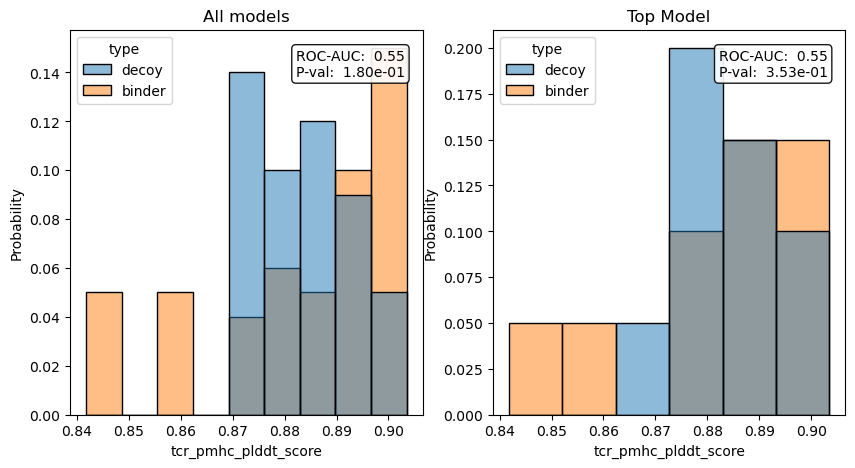

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

roc = roc_auc_score(chai_scores['label'], chai_scores['tcr_pmhc_plddt_score'])
stat, p_val = ranksums(
    chai_scores.query("type == 'binder'")['tcr_pmhc_plddt_score'],
    chai_scores.query("type == 'decoy'")['tcr_pmhc_plddt_score'],
    alternative='greater',
)

sns.histplot(chai_scores, x='tcr_pmhc_plddt_score', hue='type', stat='probability', ax=ax1)
ax1.set_title('All models')
ax1.text(
    0.95,
    0.95,
    f'ROC-AUC: {roc: .2f}\nP-val: {p_val: .2e}',
    transform=ax1.transAxes,
    verticalalignment='top',
    horizontalalignment='right',
    bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
)

# Top Model
roc = roc_auc_score(
    chai_scores.query('model_number == 0')['label'], chai_scores.query('model_number == 0')['tcr_pmhc_plddt_score']
)
stat, p_val = ranksums(
    chai_scores.query("model_number == 0 and type == 'binder'")['tcr_pmhc_plddt_score'],
    chai_scores.query("model_number == 0 and type == 'decoy'")['tcr_pmhc_plddt_score'],
    alternative='greater',
)

ax2.text(
    0.95,
    0.95,
    f'ROC-AUC: {roc: .2f}\nP-val: {p_val: .2e}',
    transform=ax2.transAxes,
    verticalalignment='top',
    horizontalalignment='right',
    bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
)
sns.histplot(chai_scores.query('model_number == 0'), x='tcr_pmhc_plddt_score', hue='type', stat='probability', ax=ax2)
ax2.set_title('Top Model')

plt.show()

In [15]:
specific_confidence_scores = []

for path in glob.glob('../data/interim/structures-chai-restraints/*/confidences.model_idx_*.npz'):
    confidence_score = {}

    with np.load(path) as fh:
        confidence = dict(fh)

    structure_name = os.path.basename(os.path.dirname(path))
    model_number = int(re.match(r'confidences.model_idx_(\d+).npz', os.path.basename(path)).group(1))

    confidence_score['structure_name'] = structure_name
    confidence_score['model_number'] = model_number

    with open(f'../data/interim/sequences-and-restraints-chai/{structure_name}.fasta', 'r') as fh:
        sequences = [line.strip() for line in fh if not line.startswith('>')]

    confidence_numbering = list(
        enumerate(
            (
                (chain_type, residue)
                for chain_type, sequence in zip(CHAIN_ORDER, sequences, strict=True)
                for residue in sequence
            ),
            0,
        )
    )

    input_sequences = dict(zip(CHAIN_ORDER, sequences, strict=True))

    # Number sequences using ANARCI
    numbered_sequences = {}
    for chain_type, sequence in input_sequences.items():
        try:
            numbered_sequence, _ = anarci.number(sequence)

        except:  # noqa: E722 Anarci throws exception on B2M
            numbered_sequence = None

        if numbered_sequence:
            numbered_sequences[chain_type] = [(seq_id, olc) for seq_id, olc in numbered_sequence if olc != '-']

        else:
            numbered_sequences[chain_type] = [((res_id, ' '), olc) for res_id, olc in enumerate(sequence, 1)]

    # Calculate offset between anarci sequence and input sequences
    offsets = {
        chain_type: sequence.find(''.join([olc for _, olc in numbered_sequences[chain_type]]))
        for chain_type, sequence in input_sequences.items()
    }

    # Get relevant ranges for input sequences
    relative_ranges = {
        chain_type: tuple(
            [
                idx + offsets[chain_type]
                for idx, ((seq_id, _), _) in enumerate(numbered_sequences[chain_type])
                if seq_id in IMGT_CDR
            ]
        )
        for chain_type in ('alpha_chain', 'beta_chain')
    }

    if max([seq_id for (seq_id, _), _ in numbered_sequences['mhc_chain_1']]) > MHC_I_IMGT_BETA_HELIX_START:
        tcr_contact_positions = []

        for helix in IMGT_MHC_TCR_CONTACT_POSITIONS:
            offset = MHC_I_IMGT_BETA_HELIX_START if helix == 'beta' else 0

            for res_id in IMGT_MHC_TCR_CONTACT_POSITIONS[helix]:
                seq_id = int(''.join([char for char in res_id if char.isnumeric()])) + offset
                insert_code = (
                    ''.join(
                        [char for char in res_id if not char.isnumeric()],
                    )
                    if len([char for char in res_id if not char.isnumeric()]) > 0
                    else ' '
                )

                tcr_contact_positions.append((seq_id, insert_code))

        tcr_contact_positions = set(tcr_contact_positions)

        relative_ranges['mhc_chain_1'] = tuple(
            [
                idx + offsets['mhc_chain_1']
                for idx, (res_id, _) in enumerate(numbered_sequences['mhc_chain_1'])
                if res_id in tcr_contact_positions
            ]
        )
        relative_ranges['mhc_chain_2'] = None

    else:
        tcr_contact_positions = {'mhc_chain_1': [], 'mhc_chain_2': []}

        for helix in IMGT_MHC_TCR_CONTACT_POSITIONS:
            for res_id in IMGT_MHC_TCR_CONTACT_POSITIONS[helix]:
                seq_id = int(''.join([char for char in res_id if char.isnumeric()]))
                insert_code = (
                    ''.join(
                        [char for char in res_id if not char.isnumeric()],
                    )
                    if len([char for char in res_id if not char.isnumeric()]) > 0
                    else ' '
                )

                tcr_contact_positions['mhc_chain_1' if helix == 'alpha' else 'mhc_chain_2'].append(
                    (seq_id, insert_code)
                )

        relative_ranges['mhc_chain_1'] = tuple(
            [
                idx + offsets['mhc_chain_1']
                for idx, (res_id, _) in enumerate(numbered_sequences['mhc_chain_1'])
                if res_id in tcr_contact_positions['mhc_chain_1']
            ]
        )

        relative_ranges['mhc_chain_2'] = tuple(
            [
                idx + offsets['mhc_chain_2']
                for idx, (res_id, _) in enumerate(numbered_sequences['mhc_chain_2'])
                if res_id in tcr_contact_positions['mhc_chain_2']
            ]
        )

    relative_ranges['antigen_chain'] = [
        idx + offsets['antigen_chain'] for idx, _ in enumerate(numbered_sequences['antigen_chain'])
    ]

    # Translate ranges to concatenated PAE space
    current_chain = None
    relative_offset = {}

    for pae_idx, (chain_type, _) in confidence_numbering:
        if chain_type != current_chain:
            relative_offset[chain_type] = pae_idx
            current_chain = chain_type

    ranges = {
        chain_type: [idx + relative_offset[chain_type] for idx in relative_range]
        for chain_type, relative_range in relative_ranges.items()
        if relative_range is not None
    }

    tcr_idxs = np.array(
        [idx for chain_type, range_ in ranges.items() for idx in range_ if chain_type in ('alpha_chain', 'beta_chain')]
    )
    pmhc_idxs = np.array(
        [
            idx
            for chain_type, range_ in ranges.items()
            for idx in range_
            if chain_type not in ('alpha_chain', 'beta_chain')
        ]
    )

    confidence_score['cdr_pmhc_pae_score'] = np.mean(np.array(confidence['pae'])[np.ix_(tcr_idxs, pmhc_idxs)])
    confidence_score['cdr_pmhc_pde_score'] = np.mean(np.array(confidence['pde'])[np.ix_(tcr_idxs, pmhc_idxs)])
    confidence_score['cdr_pmhc_plddt_score'] = np.mean(
        np.array(confidence['plddt'])[np.concatenate([tcr_idxs, pmhc_idxs])]
    )

    specific_confidence_scores.append(confidence_score)

specific_confidence_scores = pd.DataFrame(specific_confidence_scores)

Error: Something really went wrong that has not been handled
'C'
Error: Something really went wrong that has not been handled
'C'
Error: Something really went wrong that has not been handled
'C'
Error: Something really went wrong that has not been handled
'C'
Error: Something really went wrong that has not been handled
'C'
Error: Something really went wrong that has not been handled
'C'
Error: Something really went wrong that has not been handled
'C'
Error: Something really went wrong that has not been handled
'C'
Error: Something really went wrong that has not been handled
'C'
Error: Something really went wrong that has not been handled
'C'
Error: Something really went wrong that has not been handled
'C'
Error: Something really went wrong that has not been handled
'C'
Error: Something really went wrong that has not been handled
'C'
Error: Something really went wrong that has not been handled
'C'
Error: Something really went wrong that has not been handled
'C'
Error: Something really w

In [16]:
chai_scores = chai_scores.merge(specific_confidence_scores, how='inner', on=['structure_name', 'model_number'])

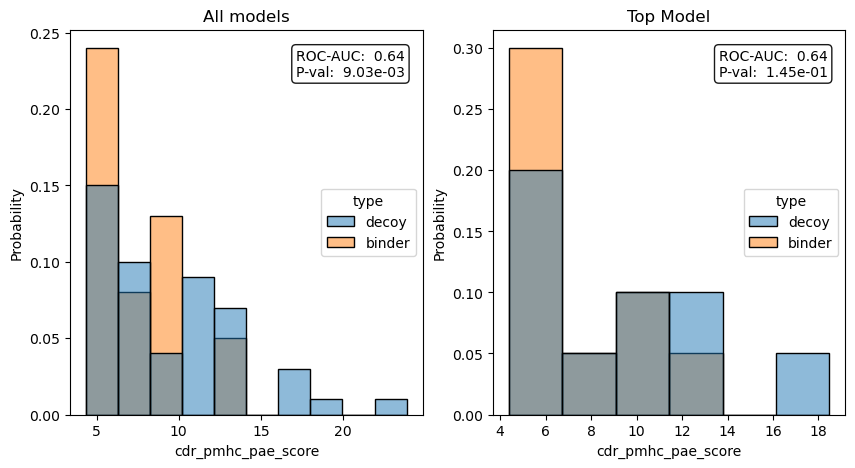

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

roc = 1 - roc_auc_score(chai_scores['label'], chai_scores['cdr_pmhc_pae_score'])
stat, p_val = ranksums(
    chai_scores.query("type == 'binder'")['cdr_pmhc_pae_score'],
    chai_scores.query("type == 'decoy'")['cdr_pmhc_pae_score'],
    alternative='less',
)

sns.histplot(chai_scores, x='cdr_pmhc_pae_score', hue='type', stat='probability', ax=ax1)
ax1.set_title('All models')
ax1.text(
    0.95,
    0.95,
    f'ROC-AUC: {roc: .2f}\nP-val: {p_val: .2e}',
    transform=ax1.transAxes,
    verticalalignment='top',
    horizontalalignment='right',
    bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
)

# Top Model
roc = 1 - roc_auc_score(
    chai_scores.query('model_number == 0')['label'], chai_scores.query('model_number == 0')['cdr_pmhc_pae_score']
)
stat, p_val = ranksums(
    chai_scores.query("model_number == 0 and type == 'binder'")['cdr_pmhc_pae_score'],
    chai_scores.query("model_number == 0 and type == 'decoy'")['cdr_pmhc_pae_score'],
    alternative='less',
)

ax2.text(
    0.95,
    0.95,
    f'ROC-AUC: {roc: .2f}\nP-val: {p_val: .2e}',
    transform=ax2.transAxes,
    verticalalignment='top',
    horizontalalignment='right',
    bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
)
sns.histplot(chai_scores.query('model_number == 0'), x='cdr_pmhc_pae_score', hue='type', stat='probability', ax=ax2)
ax2.set_title('Top Model')

plt.show()

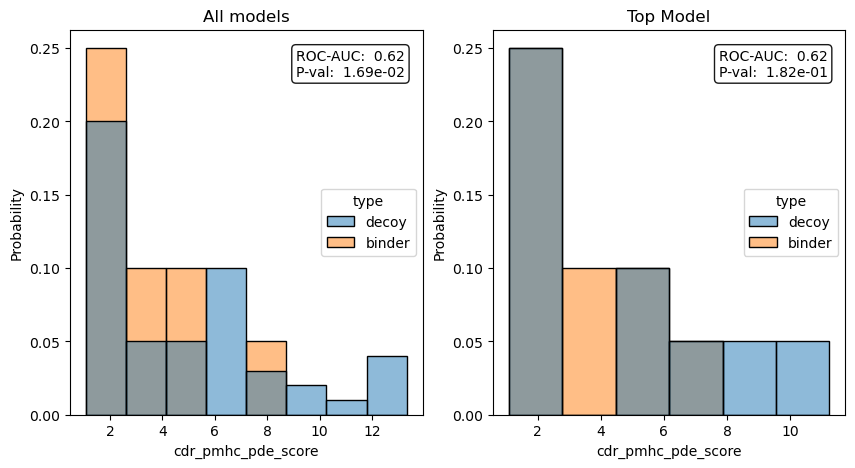

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

roc = 1 - roc_auc_score(chai_scores['label'], chai_scores['cdr_pmhc_pde_score'])
stat, p_val = ranksums(
    chai_scores.query("type == 'binder'")['cdr_pmhc_pde_score'],
    chai_scores.query("type == 'decoy'")['cdr_pmhc_pde_score'],
    alternative='less',
)

sns.histplot(chai_scores, x='cdr_pmhc_pde_score', hue='type', stat='probability', ax=ax1)
ax1.set_title('All models')
ax1.text(
    0.95,
    0.95,
    f'ROC-AUC: {roc: .2f}\nP-val: {p_val: .2e}',
    transform=ax1.transAxes,
    verticalalignment='top',
    horizontalalignment='right',
    bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
)

# Top Model
roc = 1 - roc_auc_score(
    chai_scores.query('model_number == 0')['label'], chai_scores.query('model_number == 0')['cdr_pmhc_pde_score']
)
stat, p_val = ranksums(
    chai_scores.query("model_number == 0 and type == 'binder'")['cdr_pmhc_pde_score'],
    chai_scores.query("model_number == 0 and type == 'decoy'")['cdr_pmhc_pde_score'],
    alternative='less',
)

ax2.text(
    0.95,
    0.95,
    f'ROC-AUC: {roc: .2f}\nP-val: {p_val: .2e}',
    transform=ax2.transAxes,
    verticalalignment='top',
    horizontalalignment='right',
    bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
)
sns.histplot(chai_scores.query('model_number == 0'), x='cdr_pmhc_pde_score', hue='type', stat='probability', ax=ax2)
ax2.set_title('Top Model')

plt.show()

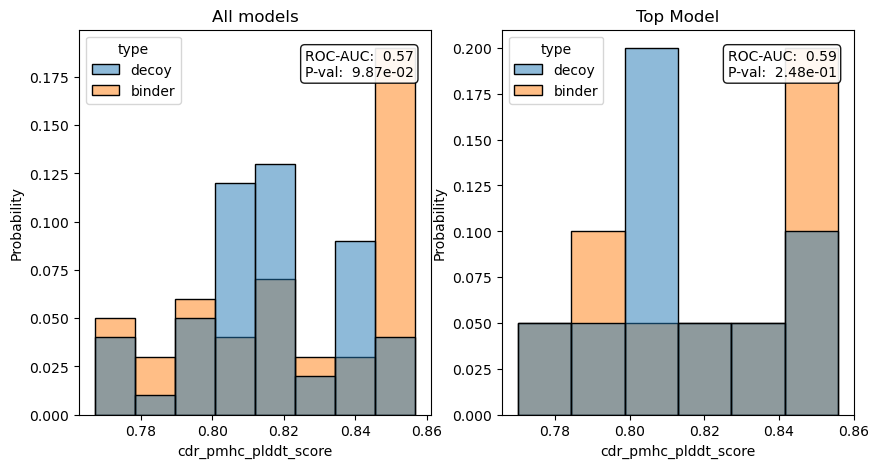

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

roc = roc_auc_score(chai_scores['label'], chai_scores['cdr_pmhc_plddt_score'])
stat, p_val = ranksums(
    chai_scores.query("type == 'binder'")['cdr_pmhc_plddt_score'],
    chai_scores.query("type == 'decoy'")['cdr_pmhc_plddt_score'],
    alternative='greater',
)

sns.histplot(chai_scores, x='cdr_pmhc_plddt_score', hue='type', stat='probability', ax=ax1)
ax1.set_title('All models')
ax1.text(
    0.95,
    0.95,
    f'ROC-AUC: {roc: .2f}\nP-val: {p_val: .2e}',
    transform=ax1.transAxes,
    verticalalignment='top',
    horizontalalignment='right',
    bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
)

# Top Model
roc = roc_auc_score(
    chai_scores.query('model_number == 0')['label'], chai_scores.query('model_number == 0')['cdr_pmhc_plddt_score']
)
stat, p_val = ranksums(
    chai_scores.query("model_number == 0 and type == 'binder'")['cdr_pmhc_plddt_score'],
    chai_scores.query("model_number == 0 and type == 'decoy'")['cdr_pmhc_plddt_score'],
    alternative='greater',
)

ax2.text(
    0.95,
    0.95,
    f'ROC-AUC: {roc: .2f}\nP-val: {p_val: .2e}',
    transform=ax2.transAxes,
    verticalalignment='top',
    horizontalalignment='right',
    bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
)
sns.histplot(chai_scores.query('model_number == 0'), x='cdr_pmhc_plddt_score', hue='type', stat='probability', ax=ax2)
ax2.set_title('Top Model')

plt.show()